<a href="https://colab.research.google.com/github/LinaMariaCastro/curso-ia-para-economia/blob/main/clases/4_Aprendizaje_no_supervisado/3_Taller_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** [Lina María Castro](https://www.linkedin.com/in/lina-maria-castro)  
- 📧 **Email:** [lmcastroco@gmail.com](mailto:lmcastroco@gmail.com)  
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# **Taller: Creación de un Índice de Clima de Inversión con Análisis de Componentes Principales (PCA)**

In [37]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**IMPORTANTE**: Guarda una copia de este notebook en tu Google Drive o computador.

**Taller en parejas**

**Nombres estudiantes:**
- Juan Pablo Lozano Mendez

**Forma de entrega:**

- Nombrar el archivo de la siguiente forma:“Taller_PCA_apellidos.ipynb”.
- Suba el Jupyter Notebook a su cuenta en Github y envíe el link en el siguiente Forms: https://forms.cloud.microsoft/r/ZZX1AFUsPP.

**IMPORTANTE:** No se recibirán talleres en Google Colab, el notebook debe estar subido en Github.

**Plazo de entrega:**

21 de octubre de 2026, máximo a las 11:59 p.m. Tenga en cuenta que luego de esa hora el formulario en forms se cierra. El Jupupyter Notebook también debe quedar subido en Github antes de esa hora.

**Instrucciones Generales:**

Completa el código en las celdas marcadas con `### TU CÓDIGO AQUÍ ###`. Puedes añadir más celdas si lo requieres.

### Contexto

**Escenario:** Eres un científico de datos recién contratado como consultor experto por el **Ministerio de Comercio, Industria y Turismo (MinCIT)** de Colombia. Tu tarea principal es crear un **'Índice de Clima para la Inversión'** cuantitativo que permita clasificar y comparar el entorno competitivo de los países de América Latina y el Caribe. Este índice orientará las estrategias de integración regional y las políticas para atraer Inversión Extranjera Directa (IED).

**Objetivo:** Utilizando la base de datos de indicadores provista (preparada para este análisis) y la técnica de **Análisis de Componentes Principales (PCA)**, deberás extraer la "variable latente" que resume el clima de inversión, interpretar sus pesos económicos y presentar un ranking de países con recomendaciones ejecutivas.


## Ejercicio 1: Configuración Inicial, Carga y Exploración de Datos

1.1 Importa las librerías necesarias

In [38]:
### TU CÓDIGO AQUÍ ###
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

In [39]:
# Configuraciones de visualización
pd.options.display.max_columns = None
pd.options.display.float_format = '{:,.2f}'.format
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

In [40]:
import os
from google.colab import drive, files
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [41]:
path = '/content/drive/MyDrive/Curso_IA_20262/4_Aprendizaje_no_supervisado'
os.chdir(path)

1.2 Carga el dataset "Indicators.csv" que se encuentra en el repositorio del curso, carpeta "datasets". El dataframe debe llamarse "df_indicators".

In [42]:
df_indicators = pd.read_csv('Indicators.csv')

In [43]:
# Debe ser (121, 4)
print("Dimensiones del DataFrame Indicators:")
print(df_indicators.shape)

Dimensiones del DataFrame Indicators:
(121, 4)


In [44]:
print("\nInformación general del DataFrame:")
df_indicators.info()


Información general del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CountryCode    121 non-null    object 
 1   IndicatorCode  121 non-null    object 
 2   Year           121 non-null    int64  
 3   Value          121 non-null    float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.9+ KB


1.3 Carga el dataset "Country.csv" que se encuentra en el repositorio del curso, carpeta "datasets". El dataframe debe llamarse "df_countries".

In [45]:
### TU CÓDIGO AQUÍ ###
df_countries = pd.read_csv('Country.csv')

In [46]:
# Debe ser (14, 3)
print("Dimensiones del DataFrame Countries:")
print(df_countries.shape)

Dimensiones del DataFrame Countries:
(14, 3)


In [47]:
print("\nInformación general del DataFrame:")
df_countries.info()


Información general del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   CountryCode  14 non-null     object
 1   ShortName    14 non-null     object
 2   Region       14 non-null     object
dtypes: object(3)
memory usage: 468.0+ bytes


### Ejercicio 2: Selección y Preparación de Datos

Para el análisis del MinCIT, hemos preseleccionado un conjunto de variables clave.

2.1. Utiliza el diccionario para modificar los códigos de los indicadores por sus descripciones

In [48]:
nombre_indicadores = {
    'NV.AGR.TOTL.ZS': 'Agricultura (% del PIB)',
    'NE.TRD.GNFS.ZS': 'Comercio (% del PIB)',
    'NY.GDP.MKTP.KD.ZG': 'Crecimiento del PIB (%)',
    'FP.CPI.TOTL.ZG': 'Inflación (%)',
    'GC.DOD.TOTL.GD.ZS': 'Deuda del gob. central (% del PIB)',
    'SE.XPD.TOTL.GD.ZS': 'Gasto en educación (% del PIB)',
    'SH.XPD.CHEX.GD.ZS': 'Gasto en salud (% del PIB)',
    'IQ.CPA.BREG.XQ': 'Facilidad para hacer negocios',
    'IC.LGL.DURS': 'Días para cumplir contratos',
    'TX.VAL.MRCH.XD.WD': 'Exportaciones (US$)',
    'TM.VAL.MRCH.XD.WD': 'Importaciones (US$)'
}

In [49]:
### TU CÓDIGO AQUÍ ###
df_indicators["IndicatorCode"] = df_indicators["IndicatorCode"].replace(nombre_indicadores)
df_indicators.head()

,CountryCode,IndicatorCode,Year,Value
0,CHL,Agricultura (% del PIB),2014,6.75
1,CHL,Comercio (% del PIB),2014,74.31
2,CHL,Crecimiento del PIB (%),2014,7.65
3,CHL,Inflación (%),2014,12.62
4,CHL,Deuda del gob. central (% del PIB),2014,42.83


2.2. Utiliza pivot table para crear un nuevo dataframe donde se encuentren los países como filas y los indicadores como columnas. Llama a este dataframe "df_pivot". No olvides colocar .reset_index() para que la columna de código de países quede como una columna y no como el índice.

In [50]:
### TU CÓDIGO AQUÍ ###
df_pivot= df_indicators.pivot_table(columns='IndicatorCode', values='Value', index='CountryCode').reset_index()
df_pivot.head(20)

IndicatorCode,CountryCode,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%)
0,ARG,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28
1,BOL,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05
2,BRA,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60
3,CHL,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62
4,COL,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61
5,CRI,8.11,70.86,5.88,NaN,610.31,"78,236,959,844.64",5.53,5.64,6.77,"72,324,083,969.39",8.49
6,DEU,NaN,NaN,1.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,ECU,10.88,54.23,1.82,63.47,739.26,"45,656,553,608.63",3.49,3.89,6.18,"39,525,318,329.77",28.66
8,MEX,9.27,49.22,4.85,52.55,614.33,"64,056,943,191.53",4.36,5.48,NaN,"59,903,958,738.66",15.52
9,PAN,5.80,NaN,6.89,43.42,555.93,"83,978,447,805.32",5.40,5.95,7.72,"76,338,244,613.60",8.11


2.3. Crea el dataframe "df_final", realizando un merge entre "df_pivot" y "df_countries" con el fin de agregar el nombre de los países.

In [51]:
### TU CÓDIGO AQUÍ ###
#Unir
df_final = pd.merge(df_pivot, df_countries, on='CountryCode')
df_final.head()
#Cambiar nombre


,CountryCode,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),ShortName,Region
0,ARG,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28,Argentina,Latin America & Caribbean
1,BOL,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05,Bolivia,Latin America & Caribbean
2,BRA,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60,Brasil,Latin America & Caribbean
3,CHL,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,Chile,Latin America & Caribbean
4,COL,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,Colombia,Latin America & Caribbean


2.4. Elimina las columnas "Region" y "CountryCode" y establece la columna 'ShortName' como el índice del dataframe

In [52]:
### TU CÓDIGO AQUÍ ###
df_final.drop(['Region', 'CountryCode'], axis=1, inplace=True)
df_final.set_index('ShortName', inplace=True)


### Ejercicio 3: Limpieza de Datos (Imputación de Valores Faltantes)

En la vida real de un economista, los datos tienen huecos. El PCA requiere bases completas. Usaremos una estrategia de imputación por la media para resolver los NaN.

3.1. Revisa cuántos valores faltantes hay en cada columna

In [53]:
### TU CÓDIGO AQUÍ ###
df_final.isna().sum()

,0
Agricultura (% del PIB),4
Comercio (% del PIB),3
Crecimiento del PIB (%),0
Deuda del gob. central (% del PIB),4
Días para cumplir contratos,2
Exportaciones (US$),3
Facilidad para hacer negocios,5
Gasto en educación (% del PIB),3
Gasto en salud (% del PIB),4
Importaciones (US$),3


3.2. Para cada columna, utiliza el promedio del resto de países de Latinoamérica para imputar los valores faltantes. El resultado debe quedar en un dataframe llamado "df_final_imputed". Al final revisa que no haya quedado ningún valor faltante en las columnas del dataframe.

In [54]:
### TU CÓDIGO AQUÍ ###
df_final_imputed = df_final.copy()

for country in df_final_imputed.columns:
    df_final_imputed[country] = df_final_imputed[country].fillna(df_final_imputed[country].mean())

df_final_imputed.isna().sum()
df_final_imputed

,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%)
ShortName,,,,,,,,,,,
Argentina,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28
Bolivia,8.86,54.39,1.76,66.69,798.96,"39,036,984,373.93",3.96,5.37,5.05,"36,977,180,000.81",36.05
Brasil,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60
Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62
Colombia,6.92,59.96,6.60,47.95,633.90,"56,527,087,039.04",3.96,6.34,6.30,"67,424,196,254.97",11.61
Costa Rica,8.11,70.86,5.88,58.75,610.31,"78,236,959,844.64",5.53,5.64,6.77,"72,324,083,969.39",8.49
Germany,8.86,56.08,1.90,58.75,700.28,"56,527,087,039.04",3.96,5.17,6.24,"51,667,740,842.74",22.59
Ecuador,10.88,54.23,1.82,63.47,739.26,"45,656,553,608.63",3.49,3.89,6.18,"39,525,318,329.77",28.66
México,9.27,49.22,4.85,52.55,614.33,"64,056,943,191.53",4.36,5.48,6.24,"59,903,958,738.66",15.52


### Ejercicio 4: Matriz de Correlaciones y Estandarización de Variables

4.1. Grafica un mapa de calor para ver las correlaciones entre las variables.

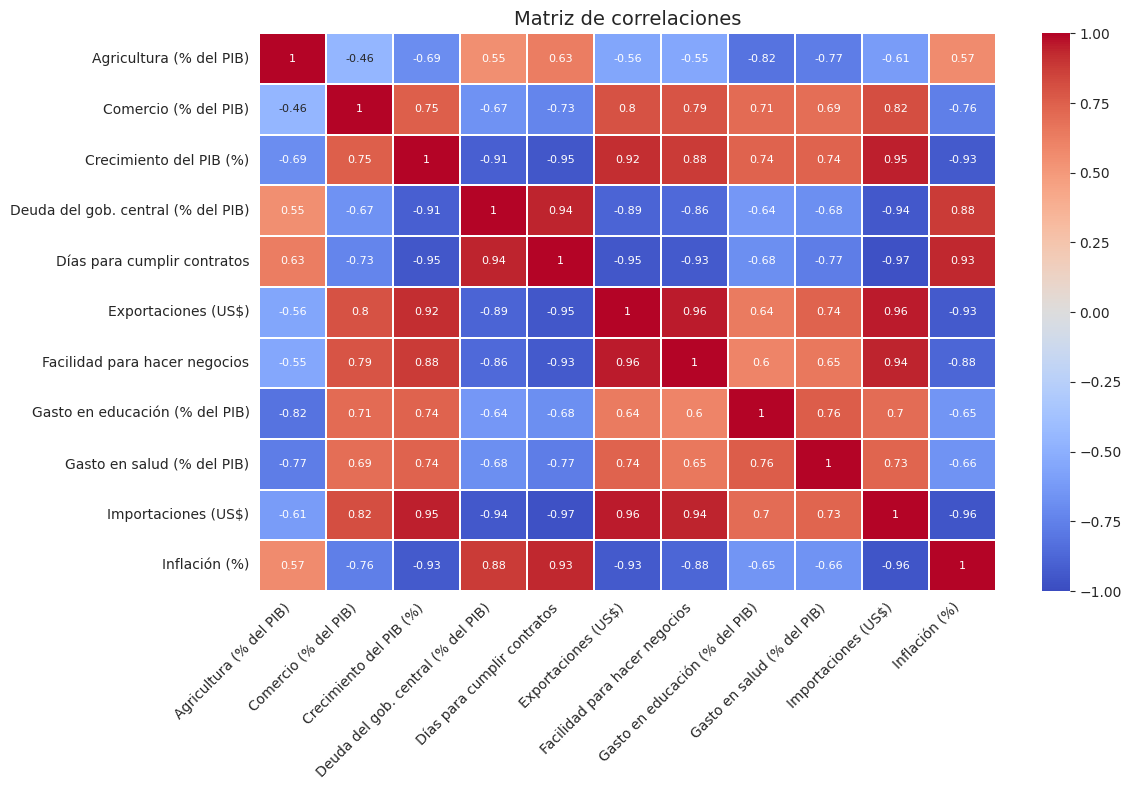

In [66]:
### TU CÓDIGO AQUÍ ###
corr = df_final_imputed.corr(). round(2)
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, vmin=-1, vmax=1, linewidths=0.3, annot_kws={'size': 8})
plt.title('Matriz de correlaciones', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

4.2. Interpreta los resultados resaltando las correlaciones más relevantes.

In [67]:
# En general, todas las variables se presentan varios casos de correlación, en algunos casos muy relevantes, dentro de las más relevantes se evidencia
# correlación en importaciones con días para cumplir contratos, importaciones con inflacion y facilidad para hacer negocios con exportaciones,
# en la cual me llama la atención la relacion negativa entre importación con inflación, ya que esto podría ser contraintuitivo,
# ya que normalmetne si suben los precios de manera interna se suele considerar la importaciión de bienes, por lo cual en la región podrían
# presentarse algunos casos especificos de consumo que no permiten la llegada de importaciones.#


4.3. Las exportaciones están en miles de millones de dólares y el crecimiento en porcentajes de un dígito. PCA busca varianzas, por lo que estandarizar (Media 0, Desviación 1) es un paso matemático obligatorio para no sesgar el modelo hacia las variables nominales grandes.  Estandariza todas las variables del dataframe y almacena el resultado en X_scaled.

In [56]:
### TU CÓDIGO AQUÍ ###
stand = StandardScaler()
X_scaled = stand.fit_transform(df_final_imputed)
X_scaled

array([[ 1.56751909e+00, -2.32214925e+00, -1.55490929e+00,
         1.41734406e+00,  1.65462324e+00, -1.67830091e+00,
        -1.45497675e+00, -2.80876841e+00, -2.17343045e+00,
        -1.67603381e+00,  1.66608784e+00],
       [-9.69817622e-16, -1.65234419e-01, -7.04531874e-01,
         7.85802281e-01,  9.42751202e-01, -8.07009683e-01,
         3.65012495e-16,  2.00383429e-01, -1.20640046e+00,
        -7.32586119e-01,  1.03366672e+00],
       [ 2.14398279e+00,  4.03097795e-01, -3.86677474e-01,
        -1.53937027e-01,  3.95565696e-01, -2.22965190e-02,
        -3.21553933e-01, -6.16134769e-01, -9.44212581e-01,
        -8.18476741e-02,  2.31596854e-01],
       [-1.15394252e+00,  1.79017362e+00,  1.56397425e+00,
        -1.57585379e+00, -1.57008213e+00,  1.56950572e+00,
         1.57883382e+00,  1.22258235e+00,  2.05907528e+00,
         1.43962595e+00, -7.65797604e-01],
       [-1.05714110e+00,  3.81256614e-01,  1.16013963e+00,
        -1.06920346e+00, -6.34094075e-01,  3.52027394e-16,
  

### Ejercicio 5: Aplicación de PCA

Vamos a correr PCA para identificar el número de componentes. Buscamos capturar la mayor cantidad de información (varianza) con la menor cantidad de dimensiones.

5.1. Corre PCA sobre X_scaled y calcula la varianza acumulada. Almacénala en la variable "varianza_acumulada".

In [57]:
### TU CÓDIGO AQUÍ ###
pca = PCA()
pca.fit(X_scaled)
varianza_acumulada = pca.explained_variance_ratio_.cumsum()
varianza_acumulada

array([0.80432386, 0.89486154, 0.93597174, 0.95991133, 0.97641891,
       0.9864744 , 0.99249496, 0.99665217, 0.99895635, 0.99961687,
       1.        ])

5.2. Similar a como lo vimos en clase, grafica la varianza explicada acumulada por componente.

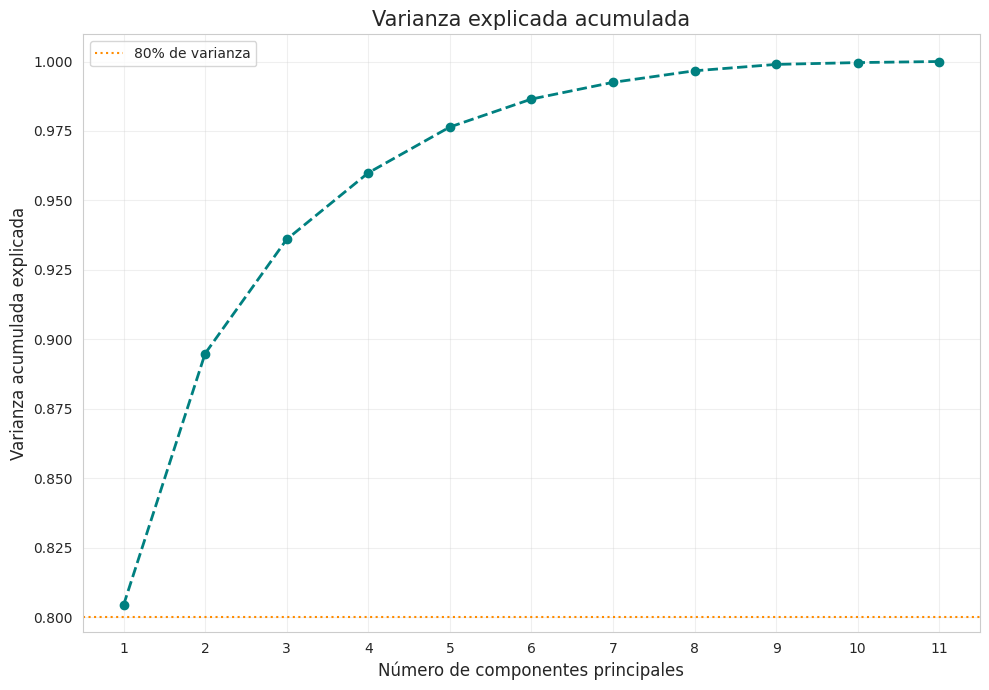

In [58]:
### TU CÓDIGO AQUÍ ###
varianza_acumulada = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(10, 7))
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker='o', linestyle='--', color='teal', linewidth=2)
plt.title('Varianza explicada acumulada', fontsize=15)
plt.xlabel('Número de componentes principales', fontsize=12)
plt.ylabel('Varianza acumulada explicada', fontsize=12)
plt.axhline(y=0.8, color='darkorange', linestyle=':', label='80% de varianza')
plt.xticks(range(1, len(varianza_acumulada) + 1))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Los dos primeros componentes explican mas del 88% de la varianza total, debido a que es un umbral alto podriamos quedarnos con dos componentes

5.3. Realiza un análisis del gráfico anterior.

### Ejercicio 6: Interpretación Económica de los Componentes (Loadings)

Nos vamos a quedar con un solo componente. Vamor a analizar qué variables originales alimentan a este componente.

6.1. Corre nuevamente el PCA, pero ahora indicando que tenga en cuenta solo 1 componente. Almacena el modelo en "pca_final" y los resultados en "X_pca".

In [59]:
### TU CÓDIGO AQUÍ ###
pca_final = PCA(n_components=1)
X_pca = pca_final.fit_transform(X_scaled)
print("Varianza explicada por CP1:", pca_final.explained_variance_ratio_[0])

Varianza explicada por CP1: 0.8043238557494737


6.2. Grafica el mapa de calor de los loadings como lo vimos en clase

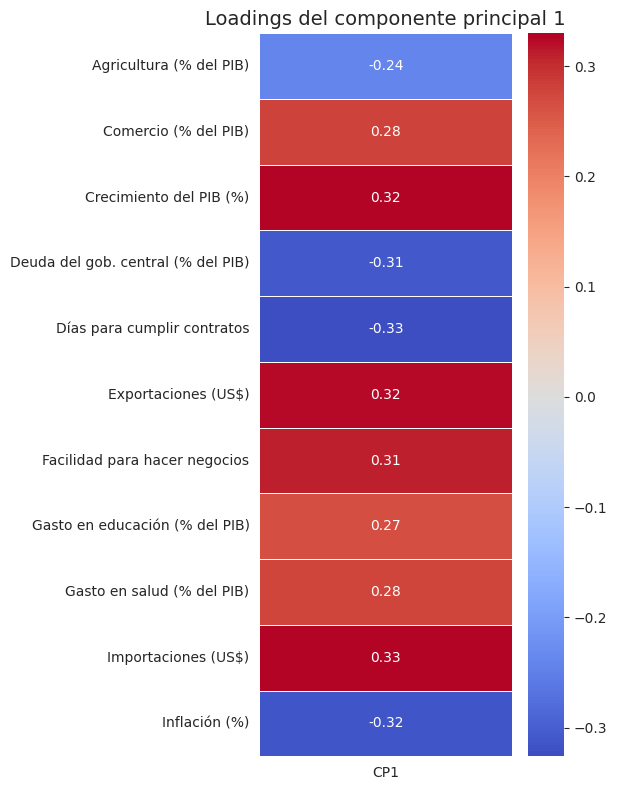

In [65]:
### TU CÓDIGO AQUÍ ###
loadings = pd.DataFrame(pca_final.components_.T, columns=['CP1'],index=df_final_imputed.columns)

plt.figure(figsize=(6, 8))
sns.heatmap(loadings, annot=True, cmap='coolwarm', center=0, linewidths=0.4, annot_kws={'size': 10})
plt.title('Loadings del componente principal 1', fontsize=14)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


6.3. Realiza una interpretación de los loadings. ¿Cuáles variables tienen las cargas altas y positivas y cuáles las cargas altas y negativas? De acuerdo con este análisis, ¿consideras que efectivamente podemos utilizar el componente 1 como un índice del clima para la inversión en cada país de Latinoamérica? ¿por qué si o por qué no?

In [ ]:
# Las variables con cargas altas y negativas son: Inflacion, Días para cumplir contrato y Deuda del gob. central.
# Las variables con cargas altas y positivas son: Importaciones, exportaciones y crecimiento del PIB
# Considero que el nuevo componene es relevante para explicar la inversión, este evidencia cargas en general homogeneas y relevantes dentro de la escala (0,3 a -0,3)
# Además que destacan variables que son determinantes para explicar la inversión, como variables de la cuenta comercial, que explica terminos de intercambio,
# inflación que usalmente al subir las tasas de interes dentro del país, suele aumentar el rendimiento del dinero y sobre todo condiciones políticas que son relevantes
# para los inversionistas, por lo que destaca la deuda del gobierno central y condiciones jurídicas.

### Ejercicio 7: Creación del 'Índice de Clima para la Inversión'

Asignaremos el CP1 como nuestro 'Índice de Clima para la Inversión' y construiremos el ranking regional.

In [61]:
df_final['Indice_Inversion'] = X_pca[:, 0]
df_final.head(14)

,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),Indice_Inversion
ShortName,,,,,,,,,,,,
Argentina,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28,-5.93
Bolivia,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05,-1.93
Brasil,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60,-1.24
Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,4.89
Colombia,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,2.13
Costa Rica,8.11,70.86,5.88,NaN,610.31,"78,236,959,844.64",5.53,5.64,6.77,"72,324,083,969.39",8.49,2.75
Germany,NaN,NaN,1.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.21
Ecuador,10.88,54.23,1.82,63.47,739.26,"45,656,553,608.63",3.49,3.89,6.18,"39,525,318,329.77",28.66,-1.79
México,9.27,49.22,4.85,52.55,614.33,"64,056,943,191.53",4.36,5.48,NaN,"59,903,958,738.66",15.52,0.97


7.1. Ordena el df_final por el índice de clima para la inversión de mayor a menor valor del índice.

In [62]:
### TU CÓDIGO AQUÍ ###
df_final = df_final.sort_values('Indice_Inversion', ascending=False)
df_final

,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),Indice_Inversion
ShortName,,,,,,,,,,,,
Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,4.89
Panamá,5.80,NaN,6.89,43.42,555.93,"83,978,447,805.32",5.40,5.95,7.72,"76,338,244,613.60",8.11,3.89
Costa Rica,8.11,70.86,5.88,NaN,610.31,"78,236,959,844.64",5.53,5.64,6.77,"72,324,083,969.39",8.49,2.75
Colombia,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,2.13
Uruguay,8.21,64.01,4.47,NaN,717.08,"63,598,148,937.21",NaN,5.63,6.65,"59,086,857,093.80",11.66,1.09
México,9.27,49.22,4.85,52.55,614.33,"64,056,943,191.53",4.36,5.48,NaN,"59,903,958,738.66",15.52,0.97
Perú,8.14,55.06,4.78,59.39,677.46,"70,328,751,109.66",4.25,5.24,6.10,NaN,16.79,0.66
United States,NaN,NaN,2.50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.14
Germany,NaN,NaN,1.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.21


7.2. Convierte 'ShortName' en una columna del dataframe.

In [63]:
### TU CÓDIGO AQUÍ ###
df_final = df_final.reset_index()
df_final.head(14)

,ShortName,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),Indice_Inversion
0,Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,4.89
1,Panamá,5.80,NaN,6.89,43.42,555.93,"83,978,447,805.32",5.40,5.95,7.72,"76,338,244,613.60",8.11,3.89
2,Costa Rica,8.11,70.86,5.88,NaN,610.31,"78,236,959,844.64",5.53,5.64,6.77,"72,324,083,969.39",8.49,2.75
3,Colombia,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,2.13
4,Uruguay,8.21,64.01,4.47,NaN,717.08,"63,598,148,937.21",NaN,5.63,6.65,"59,086,857,093.80",11.66,1.09
5,México,9.27,49.22,4.85,52.55,614.33,"64,056,943,191.53",4.36,5.48,NaN,"59,903,958,738.66",15.52,0.97
6,Perú,8.14,55.06,4.78,59.39,677.46,"70,328,751,109.66",4.25,5.24,6.10,NaN,16.79,0.66
7,United States,NaN,NaN,2.50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.14
8,Germany,NaN,NaN,1.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.21
9,Brasil,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60,-1.24


7.3. Utiliza un barplot para mostrar los resultados del Índice de Clima para la Inversión. En el eje y deben ir los países y en el eje X el puntaje del índice. No olvides colocar título al gráfico y a los ejes.

/tmp/ipykernel_2308/1432550173.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_final, x='Indice_Inversion', y='ShortName', palette='viridis')


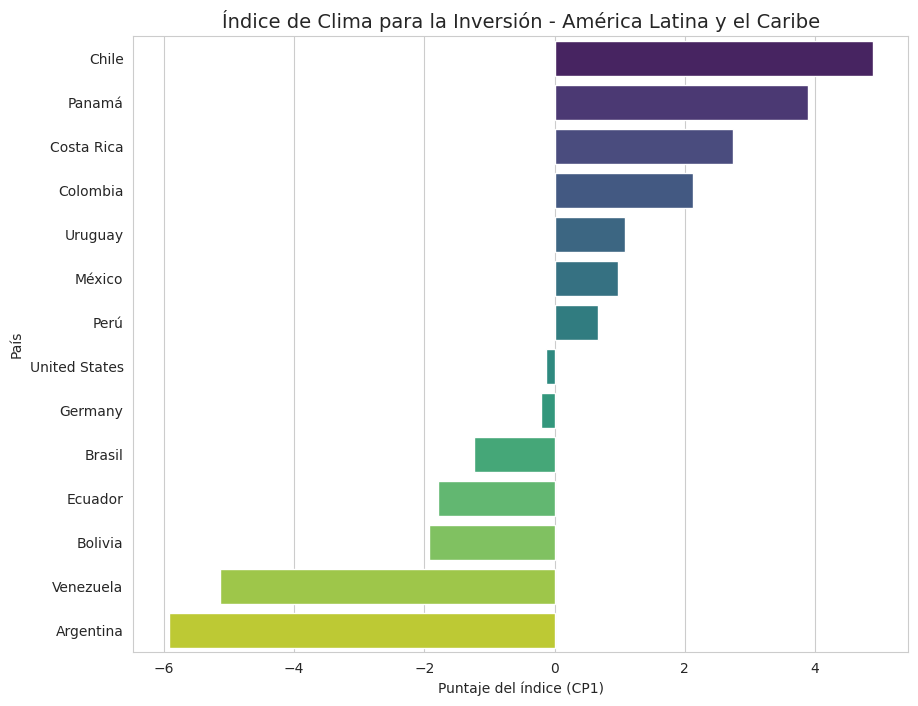

In [64]:
### TU CÓDIGO AQUÍ ###
plt.figure(figsize=(10, 8))
sns.barplot(data=df_final, x='Indice_Inversion', y='ShortName', palette='viridis')
plt.title('Índice de Clima para la Inversión - América Latina y el Caribe', fontsize=14)
plt.xlabel('Puntaje del índice (CP1)')
plt.ylabel('País')
plt.show()

7.4. Analiza los resultados del gráfico y redacta una conclusiones para el MinCIT sobre el clima de inversión en la región, quiénes son nuestros competidores en la atracción de capitales extranjeros y por qué, en qué son mejores que Colombia.

In [ ]:
# Después de crear el indice de inversión en la región, los mejores destinos para la llegada de capitales internacionales son Chile, Panamá y Costa Rica
# que están por encima de Colombia, esto puede explicarse, por que seguramente en estos países las variables con cargas altas en el componente presentan relevancia cada país,
# por ejemplo Chile, es un país que se destaca en la región por el buen uso de sus finanzas públicas, por ende en el balance del gobierno central y en su deuda total,
# mientras que Panamá y Costa rica tambien se destacan por su estabilidad política y medidas que fomentan la inversión, por lo que tambien se evidencian un incentivo
# político y jurídico para invertir. Sin embargo, Colombia en el componente tambien destaca, ya que despues de Colombia hay un brecha importante con el competir
# siguiente más proximo dentro de la escala del componente, por lo que de manera general se puede inferir que Colombia representa un buen destino de inversión dentro de la región.